# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


### Alcance y metodología

Se completan los tres TODO del [notebook de la consigna](https://github.com/cselmo/TP-Regresion-Softmax-TNG/blob/9267a2ff7839aad6fdceda2185baedabca9a4697/01_Softmax_Regression_20Newsgroups.ipynb) y se incorporan explicaciones, resultados, análisis y respuestas. Se mantienen NLTK, TF-IDF, una única capa lineal, `CrossEntropyLoss`, Adam, la partición estratificada, los rangos de búsqueda, **15 trials de 5 épocas** y el **entrenamiento final de 20 épocas**.

Para analizar dinámica y tiempos se agregan cinco comparaciones controladas sobre train/validación; no reemplazan la selección de Optuna ni usan test para elegir parámetros. También se agregan semillas explícitas, tiempos por época y registros separados por entrenamiento. Estas decisiones se explican junto al código correspondiente.

El notebook incluye las salidas de su ejecución. Con las dependencias del `README.md`, puede ejecutarse de arriba hacia abajo: descarga los datos públicos que falten y entrena todos los modelos de nuevo. Las tablas, gráficos y respuestas se pueden leer sin ejecutar código. Los tiempos y las conclusiones numéricas escritos corresponden a las salidas incluidas; otra ejecución puede tener tiempos distintos.

## 0. Setup

### Explicación: herramientas y entorno

| Herramienta | Función en este notebook |
|---|---|
| NLTK | Tokenización, stopwords inglesas, stemming de Porter y lematización con WordNet. |
| scikit-learn | Dataset, TF-IDF, separación train/validación y métricas. |
| PyTorch | Tensores, modelo lineal, autograd, CrossEntropyLoss y Adam. |
| TensorBoard | Curvas de pérdida y accuracy por época. |
| MLflow | Corridas experimentales con parámetros, métricas y modelo final. |
| Optuna | Búsqueda conjunta de hiperparámetros de texto y entrenamiento. |
| NumPy, pandas y Matplotlib | Operaciones numéricas, tablas y gráficos. |

La primera celda comprueba dependencias; no instala ni actualiza paquetes durante la ejecución. `README.md` explica cómo preparar Python y JupyterLab, y `requirements-lock.txt` fija las versiones utilizadas. El código selecciona CUDA si está disponible; las salidas incluidas se obtuvieron en CPU.

In [1]:
# Instalar las dependencias antes de abrir el notebook, según README.md.
# Esta celda comprueba que las bibliotecas principales estén disponibles.
import importlib.util
assert all(importlib.util.find_spec(p) for p in ['torch', 'mlflow', 'optuna', 'nltk', 'sklearn'])

In [2]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


C:\Alvaro\Redes Neuronales\07_TP_Softmax\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usando dispositivo: cpu


### Configuración agregada: datos y seguimiento de experimentos

Este bloque es un agregado al template para que el notebook se pueda ejecutar desde su propia carpeta y para registrar los experimentos solicitados. `datos/` recibe los recursos públicos de NLTK y 20 Newsgroups; `salidas/` recibe la base SQLite de MLflow, sus artefactos y los eventos de TensorBoard. Ambas carpetas se crean al ejecutar: no hay que descargarlas junto con la entrega.

`RUN_ID` distingue las ejecuciones en los registros; no selecciona modelos guardados. Cada Run All crea un estudio y entrena desde cero. Los historiales se conservan en variables del notebook y las tablas se calculan directamente a partir de ellas.

Se fija PyTorch en dos hilos de CPU para mantener una condición común en las mediciones. `reset_seed()` reinicia Python, NumPy y PyTorch antes de cada entrenamiento; el sampler de Optuna usa su propia semilla más adelante. Estas decisiones facilitan la comparación sin garantizar tiempos idénticos entre equipos.

In [3]:
import time
from pathlib import Path
from datetime import datetime
import pandas as pd
from IPython.display import display

DATA_DIR = Path('datos')
NLTK_DIR = DATA_DIR / 'nltk_data'
OUTPUT_DIR = Path('salidas').resolve()
NLTK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
nltk.data.path.insert(0, str(NLTK_DIR.resolve()))
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
torch.set_num_threads(2)

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

mlflow.set_tracking_uri('sqlite:///' + (OUTPUT_DIR / 'mlflow.db').as_posix())
experiment_name = 'softmax_20newsgroups'
if mlflow.get_experiment_by_name(experiment_name) is None:
    mlflow.create_experiment(experiment_name, artifact_location=(OUTPUT_DIR / 'mlartifacts').as_uri())
mlflow.set_experiment(experiment_name)
print('Ejecución:', RUN_ID, '| hilos CPU:', torch.get_num_threads())

2026/09/30 22:36:31 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/09/30 22:36:32 INFO mlflow.store.db.utils: Updating database tables


Ejecución: 20260930_223630_396045 | hilos CPU: 2


In [4]:
# Descarga inicial de los recursos indicados en la consigna.
# Si ya están en datos/nltk_data, NLTK los reutiliza.
for resource in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab']:
    assert nltk.download(resource, download_dir=str(NLTK_DIR), quiet=True)
print('Recursos NLTK disponibles.')

Recursos NLTK disponibles.


### Explicación: semillas y recursos de lenguaje

`SEED = 42` fija Python, NumPy y PyTorch. La instrumentación reinicia estas semillas antes de cada entrenamiento y fija `TPESampler(seed=42)`, con trials secuenciales. El split se mantiene con `random_state=42`. Se usan dos hilos de CPU y el mismo entorno; la reproducibilidad numérica no implica tiempos idénticos ni igualdad entre hardware/versiones.

NLTK requiere recursos además del paquete: stopwords inglesas, WordNet, OMW 1.4 y los tokenizadores `punkt`/`punkt_tab`. Se reutilizan en `datos/nltk_data` y solo se descargan si faltan. WordNet conserva el POS nominal predeterminado del código del profesor.

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [5]:
newsgroups_train = fetch_20newsgroups(data_home=str(DATA_DIR / "scikit_learn"), subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(data_home=str(DATA_DIR / "scikit_learn"), subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### Explicación: documentos, etiquetas y particiones

`newsgroups_train.data` y `newsgroups_test.data` son listas de documentos. Sus arreglos `target` contienen índices enteros de clase; `target_names` permite interpretar esos índices. Se utilizan las veinte categorías, con las particiones oficiales: **11.314 documentos en train y 7.532 en test**, comprobadas al preparar el entorno.

Quitar encabezados, firmas y citas reduce señales que podrían revelar la categoría sin reconocer el tema del documento. No se copian el muestreo ni el filtrado de documentos cortos del ejemplo de cuatro categorías usado en clase.

Durante la búsqueda se separará validación del train oficial. Train ajusta pesos y representación; validación permite elegir hiperparámetros; test se reserva para evaluar la configuración ya fijada. Esta separación sigue el criterio de los apuntes de regularización, págs. 7–13.

## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

### Explicación del TODO 1: preprocesamiento configurable

Se conserva la secuencia del código inicial: minúsculas, `word_tokenize`, filtro `isalpha()`, eliminación opcional de stopwords y normalización. La entrada y la salida son strings; los tokens se unen con espacios para pasarlos al vectorizador. Las comprensiones de listas siguen el estilo de las funciones de preprocesamiento del notebook hecho en clase.

`STOP_WORDS` es un conjunto para consultar pertenencia. El filtro se aplica antes de stemming o lematización, cuando los tokens todavía tienen sus formas originales en minúsculas. Porter y WordNet se crean una vez y se reutilizan. Las dos opciones booleanas de stopwords y las tres normalizaciones producen seis configuraciones. Un texto vacío, o sin tokens alfabéticos, produce un string vacío.

**Aclaración sobre el ejemplo de lematización de la consigna:** `lemmatize(token)` usa por defecto `pos='n'` (sustantivo). Por ello `dogs` puede pasar a `dog`, pero `running` no necesariamente pasa a `run`; para este último caso haría falta tratarlo como verbo. Se conserva la llamada pedida, sin agregar análisis gramatical. [Referencia de WordNetLemmatizer](https://www.nltk.org/api/nltk.stem.wordnet.html).

El control siguiente permite comparar las seis transformaciones sobre la misma oración. Esa comparación describe el efecto sobre el texto; la conveniencia de cada configuración se determinará luego con validación.

In [6]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # Filtrar stopwords antes de normalizar las palabras.
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # Aplicar una de las alternativas indicadas en la consigna.
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)


In [7]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin


normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

### Explicación del TODO 2: ajuste de TF-IDF

El vectorizador aprende del entrenamiento dos elementos: qué términos forman el vocabulario y el peso IDF de cada uno. `fit_transform(train_texts)` realiza ese ajuste y genera la matriz de train; `transform(test_texts)` reutiliza lo aprendido. En la búsqueda, el argumento llamado `test_texts` recibirá en realidad los textos de validación. Nunca se vuelve a ajustar el vocabulario con ese segundo conjunto.

Si hay $N$ documentos y $D$ términos admitidos, la matriz tiene forma $N\times D$. Se devuelve dispersa: almacena principalmente sus entradas no nulas. `D` puede ser menor que `max_features`. Mantener el mismo vectorizador conserva el significado y orden de las columnas en ambos conjuntos; un término exclusivo del segundo conjunto no se incorpora al vocabulario.

Se pasan únicamente los tres hiperparámetros que solicita el profesor. Los demás conservan sus valores predeterminados, entre ellos IDF suavizado y normalización L2 por documento. Esto difiere del ejemplo didáctico de clase que desactiva ambas opciones. El patrón predeterminado de tokenización del vectorizador también descarta palabras de un solo carácter. La normalización L2 del vector no equivale a regularizar los pesos del clasificador. [Referencia de TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).

In [8]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # Aprender el vocabulario y el IDF únicamente con entrenamiento.
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df,
    )
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


In [9]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

### Explicación del TODO 3: capa lineal y logits

El modelo sigue la estructura de `PyTorch.ipynb` de clase: hereda de `nn.Module`, registra una capa `nn.Linear` y define el cálculo en `forward`. Aquí no se necesita aplanar imágenes: las entradas TF-IDF ya tienen forma `[batch_size, input_dim]`.

Con $D$ entradas y $C$ clases:

$$z=Wx+b,\qquad W\in\mathbb{R}^{C\times D},\quad b\in\mathbb{R}^{C}.$$

La salida tiene forma `[batch_size, num_classes]`. Contiene un **logit** por clase, no probabilidades; sus valores pueden ser negativos y no tienen que sumar uno. El modelo tiene $CD+C$ parámetros con bias, y ninguna capa oculta.

Softmax permite interpretar los logits como probabilidades, $p_k=e^{z_k}/\sum_j e^{z_j}$. Sin embargo, `CrossEntropyLoss` recibe directamente los logits e incorpora la operación equivalente a `LogSoftmax` seguida de `NLLLoss`. Aplicar softmax previamente cambiaría el objetivo y sus gradientes. Para predecir basta `argmax` sobre los logits, porque softmax conserva su orden. [Referencia de CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html).

El control del profesor verifica que cuatro vectores de cincuenta componentes producen cuatro salidas de veinte componentes. No evalúa todavía si el clasificador aprendió.

In [10]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # Una única capa lineal: un logit por clase.
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # CrossEntropyLoss recibe logits, sin softmax previo.
        return self.linear(x)


In [11]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)


Shape de salida OK: torch.Size([4, 20])


## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [12]:
%load_ext tensorboard


### Explicación: tensores y ciclo de entrenamiento provisto

`to_tensor_dataset` convierte TF-IDF a `float32`, densifica y crea el tensor a partir del arreglo NumPy. Las etiquetas se convierten a `long`, con un índice de clase por muestra. `TensorDataset` mantiene la correspondencia entre cada entrada y su etiqueta; `DataLoader` agrupa esos pares en mini-batches. Densificar requiere memoria proporcional a $N\times D$, además de las copias temporales, y el tamaño efectivo importa al elegir un equipo. Las corridas completas de esta entrega se ejecutaron en la CPU local.

En cada batch, el entrenamiento provisto realiza:

1. Llevar entradas y etiquetas al dispositivo del modelo.
2. Borrar los gradientes anteriores con `optimizer.zero_grad()`.
3. Calcular logits y pérdida.
4. Ejecutar `loss.backward()` para obtener derivadas respecto de los parámetros.
5. Ejecutar `optimizer.step()` para actualizar esos parámetros.

Backpropagation calcula gradientes; Adam determina la actualización. La pérdida penaliza la probabilidad asignada a la clase correcta, mientras que accuracy cuenta cuántos `argmax` coinciden con las etiquetas. Pueden evolucionar de manera distinta.

La pérdida de cada batch se multiplica por su cantidad de muestras antes de acumularla; al dividir por el total se obtiene el promedio por documento, incluso cuando el último batch es más pequeño. Train se mide durante las actualizaciones. Validación se mide al finalizar la época, con pesos fijos, `model.eval()` y `torch.no_grad()`. Por eso las curvas no provienen de mediciones exactamente simétricas.

`history` conserva pérdida y accuracy por época. Cuando recibe un `writer`, la función también las envía a TensorBoard; las llamadas de MLflow se realizan siempre. Estos registros se conservan por corrida mediante la instrumentación siguiente; los análisis usan sus valores reales.

In [13]:
def to_tensor_dataset(X, y):
    X_dense = torch.from_numpy(X.astype(np.float32).toarray())
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax", eval_name="val"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    history.update({"epoch_seconds": [], "elapsed_seconds": []})
    for epoch in range(epochs):
        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_start = time.perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"{eval_name}_loss: {val_loss:.4f} {eval_name}_acc: {val_acc:.4f}", flush=True)

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, eval_name: val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, eval_name: val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric(f"{eval_name}_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric(f"{eval_name}_acc", val_acc, step=epoch)

        if device.type == "cuda":
            torch.cuda.synchronize()
        seconds = time.perf_counter() - epoch_start
        history["epoch_seconds"].append(seconds)
        history["elapsed_seconds"].append(sum(history["epoch_seconds"]))
        mlflow.log_metric("epoch_seconds", seconds, step=epoch)

    return history

### Registro y medición de tiempos

El loop conserva el cálculo y la actualización del profesor. Se agregan tiempos y el nombre del conjunto evaluado. `history` guarda pérdida, accuracy, segundos por época y segundos acumulados. Los historiales permanecen en memoria para construir las tablas y las figuras del notebook.

`perf_counter` mide desde antes de train hasta después de evaluación, impresión y registro de las cuatro métricas en MLflow/TensorBoard. Se excluye registrar el propio tiempo y exportar el modelo. La suma de esos intervalos se informa como tiempo de entrenamiento; preprocesamiento, vectorización y conversión a tensores se miden aparte. No se incluyen instalaciones ni descargas. En CUDA se sincroniza antes de cerrar el intervalo.

`run_experiment`, definido a continuación, crea un modelo y Adam nuevos en cada llamada, prepara los DataLoader y abre una corrida MLflow y un writer exclusivos. Al terminar, devuelve el modelo, el historial y las mediciones de esa corrida. `finally` cierra el writer incluso si ocurre un error. No carga pesos anteriores.

Las claves internas `val_*` de la función original se conservan para evitar duplicar el loop. Cuando se le pasa test en el entrenamiento final, las métricas se rotulan como **test** en MLflow, TensorBoard y gráficos. La conversión a float32 antes de densificar reduce copias en memoria sin cambiar el tensor que usa el modelo.

In [14]:
def run_experiment(name, params, X_train, y_train, X_eval, y_eval, epochs,
                   eval_name='val', vectorization_seconds=0.0):
    reset_seed()
    model_run = SoftmaxRegression(X_train.shape[1], NUM_CLASSES)
    t0 = time.perf_counter()
    tr_loader = DataLoader(to_tensor_dataset(X_train, y_train), batch_size=params['batch_size'], shuffle=True)
    ev_loader = DataLoader(to_tensor_dataset(X_eval, y_eval), batch_size=params['batch_size'], shuffle=False)
    tensor_seconds = time.perf_counter() - t0
    optimizer = optim.Adam(model_run.parameters(), lr=params['lr'])
    with mlflow.start_run(run_name=f'{RUN_ID}_{name}') as run:
        writer = SummaryWriter(log_dir=str(OUTPUT_DIR / 'runs' / RUN_ID / f'{name}_{run.info.run_id}'))
        mlflow.log_params(dict(params, epochs=epochs, seed=SEED, input_dim=X_train.shape[1],
            train_samples=len(y_train), eval_samples=len(y_eval), eval_set=eval_name,
            cpu_threads=torch.get_num_threads()))
        try:
            history_run = train_softmax_model(model_run, tr_loader, ev_loader, optimizer, epochs,
                writer=writer, run_name=name, eval_name=eval_name)
        finally:
            writer.close()
        record = dict(params=dict(params), history=history_run, mlflow_run_id=run.info.run_id,
            vectorization_seconds=vectorization_seconds, tensor_seconds=tensor_seconds,
            training_seconds=history_run['elapsed_seconds'][-1],
            updates_per_epoch=len(tr_loader), total_updates=len(tr_loader)*epochs)
        mlflow.log_metrics({'vectorization_seconds': vectorization_seconds,
            'tensor_seconds': tensor_seconds, 'training_seconds': record['training_seconds']})
    return model_run, history_run, record

## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

### Explicación: preprocesamiento compartido entre trials

El profesor precalcula las seis combinaciones de stopwords y normalización, porque son operaciones costosas que dependen de pocos parámetros. El diccionario `preprocessed_cache` mantiene esos textos **en memoria durante la ejecución**. Cada trial reutiliza la variante que le corresponde; ejecutar el notebook de nuevo vuelve a calcularlas.

Estas reglas lingüísticas no aprenden estadísticas del corpus. El vocabulario y los IDF se ajustan después del split, exclusivamente con el train de cada ensayo. Aunque el diccionario incluya textos de test, sus etiquetas y sus métricas no intervienen en la selección.

Se mide por separado el tiempo de cada variante sobre train y test completos. Este costo inicial no se atribuye al entrenamiento de un solo trial.

In [15]:
print('Precalculando las seis variantes de preprocesamiento...', flush=True)
preprocessed_cache, preprocessing_times = {}, []
for remove_stopwords in [False, True]:
    for normalization in ['none', 'stem', 'lemmatize']:
        t0 = time.perf_counter()
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        seconds = time.perf_counter() - t0
        preprocessed_cache[(remove_stopwords, normalization)] = (train_proc, test_proc)
        preprocessing_times.append(dict(remove_stopwords=remove_stopwords,
            normalization=normalization, seconds=seconds))
        print(remove_stopwords, normalization, f'{seconds:.2f} s', flush=True)
display(pd.DataFrame(preprocessing_times))

Precalculando las seis variantes de preprocesamiento...


False none 36.30 s


False stem 115.17 s


False lemmatize 66.56 s


True none 39.71 s


True stem 101.24 s


True lemmatize 67.85 s


,remove_stopwords,normalization,seconds
0,False,none,36.295937
1,False,stem,115.168609
2,False,lemmatize,66.562116
3,True,none,39.713869
4,True,stem,101.242480
5,True,lemmatize,67.853589


### Explicación: función objetivo y búsqueda de Optuna

Un `trial` es una configuración evaluada por `objective`. La función propone parámetros de representación y entrenamiento en conjunto:

| Grupo | Opciones del notebook |
|---|---|
| Stopwords / normalización | Dos alternativas booleanas y `none`, `stem` o `lemmatize`. |
| N-gramas | Unigramas o unigramas más bigramas. |
| Vocabulario | `max_features`: 2000, 5000 o 10000; `min_df`: 1, 2 o 5. |
| Entrenamiento | `lr` entre $10^{-3}$ y $10^{-1}$ en escala logarítmica; batch de 32, 64 o 128. |

Se usa el 80 % del train oficial para ajustar y el 20 % para validar. `stratify` conserva aproximadamente las proporciones de clases y `random_state=SEED` mantiene la partición entre trials. El vectorizador se crea después del split; cada modelo y cada optimizador también se crean de nuevo.

Adam es el optimizador fijado por el profesor: no se lo compara con otros aquí. El learning rate controla la escala de actualización y el batch size cambia tanto el gradiente estimado como la cantidad de actualizaciones por época. Las curvas permitirán analizar sus efectos, siguiendo el apunte de optimizadores.

`study.optimize(..., n_trials=15)` ejecutará quince entrenamientos de cinco épocas. Cada trial devuelve la **accuracy de validación de su última época**, y el estudio la maximiza. No usa F1 ni el máximo histórico de accuracy, y no realiza validación cruzada de cinco folds como el ejemplo de `GridSearchCV` de clase. La mejor configuración será la mejor entre las ensayadas con ese presupuesto, sin garantía de ser un óptimo global ni de haber convergido.

El registro agregado crea una corrida MLflow y un writer por trial, conserva las cinco épocas en `trial_records`. El estudio se crea nuevo en cada ejecución. El sampler TPE usa semilla 42. Los primeros diez trials usan la fase inicial aleatoria predeterminada; después TPE aprovecha las observaciones. Quince trials cubren una fracción pequeña del espacio: las asociaciones entre parámetros no prueban efectos causales.

In [16]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    # Partimos una porción de train como validación para la búsqueda (no usamos el test acá)
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    t0 = time.perf_counter()
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    vectorization_seconds = time.perf_counter() - t0
    _, history, record = run_experiment(f"trial_{trial.number}", dict(trial.params),
        X_tr, tr_labels, X_val, val_labels, epochs=5, vectorization_seconds=vectorization_seconds)
    trial_records[trial.number] = record
    trial.set_user_attr("training_seconds", record["training_seconds"])
    trial.set_user_attr("input_dim", X_tr.shape[1])
    return history["val_acc"][-1]


trial_records = {}
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=15, gc_after_trial=True)
print('Mejores hiperparámetros:', study.best_params)
print('Mejor accuracy de validación:', study.best_value)

[I 2026-09-30 22:48:25,205] A new study created in memory with name: no-name-986ce773-6a76-44ee-9196-8a8079c5a632


[trial_0] Epoch 1/5 - train_loss: 2.8880 train_acc: 0.4313 - val_loss: 2.7795 val_acc: 0.5466


[trial_0] Epoch 2/5 - train_loss: 2.6471 train_acc: 0.6639 - val_loss: 2.5945 val_acc: 0.5687


[trial_0] Epoch 3/5 - train_loss: 2.4396 train_acc: 0.7042 - val_loss: 2.4330 val_acc: 0.5820


[trial_0] Epoch 4/5 - train_loss: 2.2556 train_acc: 0.7271 - val_loss: 2.2924 val_acc: 0.5908


...

[trial_14] Epoch 3/5 - train_loss: 2.3907 train_acc: 0.7891 - val_loss: 2.4015 val_acc: 0.6624


[trial_14] Epoch 4/5 - train_loss: 2.1819 train_acc: 0.8304 - val_loss: 2.2476 val_acc: 0.6739


[trial_14] Epoch 5/5 - train_loss: 1.9957 train_acc: 0.8478 - val_loss: 2.1119 val_acc: 0.6867


[I 2026-09-30 22:51:04,270] Trial 14 finished with value: 0.6866990720282811 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.0010564492143776564, 'batch_size': 32}. Best is trial 2 with value: 0.7220503756076005.


Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.010968217207529524, 'batch_size': 128}
Mejor accuracy de validación: 0.7220503756076005


,trial,val_acc,remove_stopwords,normalization,ngram_range,max_features,min_df,lr,batch_size,seconds,D
2,2,0.72205,False,lemmatize,1gram,10000,2,0.01097,128,5.46251,10000
12,12,0.71984,False,lemmatize,1gram,10000,5,0.00791,128,4.58310,10000
13,13,0.71763,False,lemmatize,1gram,10000,2,0.01314,64,5.24606,10000
11,11,0.71233,False,lemmatize,1gram,10000,5,0.00568,128,4.14402,10000
9,9,0.71056,True,lemmatize,1_2gram,10000,5,0.00438,128,4.12512,10000
10,10,0.70791,False,lemmatize,1gram,10000,2,0.06539,128,4.42993,10000
3,3,0.70614,True,lemmatize,1_2gram,10000,2,0.00365,128,4.92859,10000
14,14,0.68670,False,lemmatize,1gram,10000,2,0.00106,32,7.72478,10000
5,5,0.67830,True,stem,1_2gram,10000,2,0.00112,128,4.81886,10000
4,4,0.67521,True,none,1gram,5000,5,0.01764,32,7.53816,5000


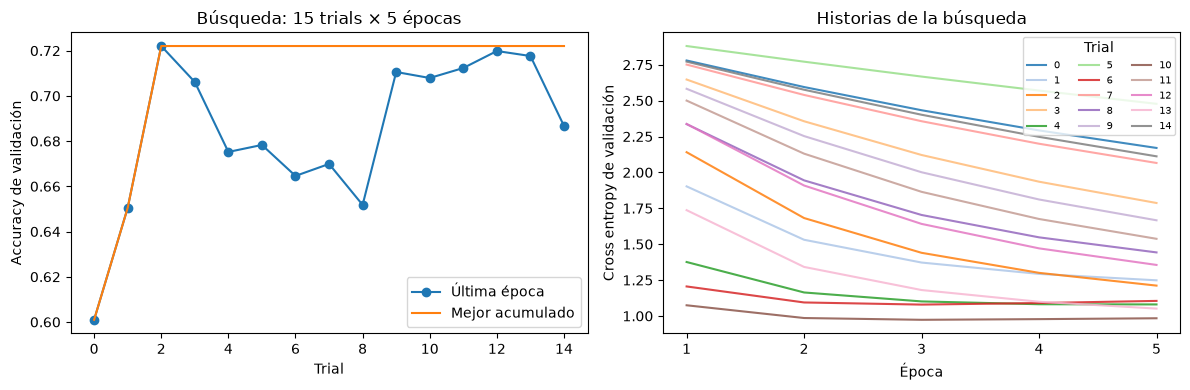

In [17]:
trial_table = pd.DataFrame([dict(trial=t.number, val_acc=t.value, **t.params,
    seconds=t.user_attrs['training_seconds'], D=t.user_attrs['input_dim']) for t in study.trials])
display(trial_table.sort_values('val_acc', ascending=False).round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(trial_table.trial, trial_table.val_acc, 'o-', label='Última época')
axes[0].plot(trial_table.trial, np.maximum.accumulate(trial_table.val_acc), label='Mejor acumulado')
axes[0].set(xlabel='Trial', ylabel='Accuracy de validación', title='Búsqueda: 15 trials × 5 épocas')
axes[0].legend()
for t in study.trials:
    h = trial_records[t.number]['history']
    axes[1].plot(range(1, 6), h['val_loss'], alpha=.85, color=plt.get_cmap('tab20')(t.number), label=str(t.number))
axes[1].set(xlabel='Época', ylabel='Cross entropy de validación', title='Historias de la búsqueda')
axes[1].legend(title='Trial', ncol=3, fontsize=7)
axes[1].set_xticks(range(1, 6))
fig.tight_layout()
plt.show()

### Análisis de la búsqueda de hiperparámetros

Se completaron **15 trials**, cada uno con 5 épocas sobre **9051 documentos de entrenamiento y 2263 de validación**. Ganó el **trial 2**, con accuracy de validación **72.21 %** en su quinta época. El segundo fue el trial 12 (71.98 %); la diferencia es **0.221 puntos porcentuales**. El peor de los quince obtuvo 60.10 %. El criterio se aplicó tal como lo define el profesor: última accuracy de validación, no mejor época ni pérdida mínima.

| Hiperparámetro elegido | Valor |
|---|---|
| Quitar stopwords | `False` |
| Normalización | `lemmatize` |
| N-gramas | `1gram` |
| Vocabulario máximo | 10000 |
| min_df | 2 |
| Learning rate de Adam | 0.01096822 |
| Batch | 128 |

El muestreo incluyó 4 configuraciones sin normalizar, 3 con stemming y 8 con lematización. Cambiaron varios factores simultáneamente, por lo que un trial ganador **no demuestra por separado** que cada una de sus opciones sea superior. Tampoco quince observaciones permiten afirmar un óptimo global. Las comparaciones controladas siguientes aíslan LR y batch manteniendo la representación.

En el ganador, train accuracy pasó de 50.94 % a 92.29 %, y val_loss de 2.1407 a 1.2115. En 13/15 trials la pérdida de validación todavía descendía entre las épocas 4 y 5: el ranking corresponde a un **presupuesto corto**, no garantiza el mismo orden al converger. No se cambió el presupuesto original en función de esa observación.

Tiempo medido acumulado de los quince entrenamientos, incluida su evaluación y el registro descrito: **72.03 s**. Vectorización: 69.99 s; conversión a tensores: 2.05 s. Son sumas de etapas instrumentadas, no tiempo total de pared del notebook: no incluyen inicialización, exportaciones, gráficos ni pausas. La caché de seis preprocesamientos costó **426.84 s** una sola vez; reutilizarla evita cobrar ese costo en cada trial. Esos costos fijos se distinguen del tiempo hasta alcanzar un criterio de desempeño.

### Comparaciones controladas de dinámica y tiempo

**Protocolo fijado antes de estas corridas:** usar la representación elegida por Optuna y el mismo split estratificado 80/20. Comparar LR = 0.001, 0.01 y 0.1 con batch 64; comparar batch = 32, 64 y 128 con LR = 0.01. Son cinco casos distintos, con referencia compartida LR 0.01 / batch 64. Adam, semilla 42 y veinte épocas en todos. Cambia un factor por comparación. No se usa test ni se reemplazan los mejores hiperparámetros originales por los de este análisis.

Definición operativa: primera época que completa **tres épocas consecutivas sin reducir el mejor val_loss de referencia en al menos 0.001** (se actualiza la referencia cuando se alcanza ese descenso). También medir tiempo hasta **accuracy de validación ≥ 0.70**. Registrar «no alcanzado» si corresponde. Ningún criterio detiene el entrenamiento. Estabilización de validación puede reflejar sobreajuste y no demuestra convergencia matemática. Se realiza una corrida por caso: los tiempos son observaciones locales, sin estimación de dispersión.

[lr_001_b64] Epoch 1/20 - train_loss: 2.9241 train_acc: 0.3852 - val_loss: 2.8494 val_acc: 0.5338


[lr_001_b64] Epoch 2/20 - train_loss: 2.7496 train_acc: 0.6935 - val_loss: 2.7162 val_acc: 0.6147


[lr_001_b64] Epoch 3/20 - train_loss: 2.5893 train_acc: 0.7618 - val_loss: 2.5923 val_acc: 0.6350


[lr_001_b64] Epoch 4/20 - train_loss: 2.4388 train_acc: 0.8022 - val_loss: 2.4776 val_acc: 0.6527


[lr_001_b64] Epoch 5/20 - train_loss: 2.2979 train_acc: 0.8202 - val_loss: 2.3709 val_acc: 0.6628


...

[lr_01_b128] Epoch 17/20 - train_loss: 0.2300 train_acc: 0.9693 - val_loss: 0.9932 val_acc: 0.7176


[lr_01_b128] Epoch 18/20 - train_loss: 0.2171 train_acc: 0.9701 - val_loss: 0.9904 val_acc: 0.7176


[lr_01_b128] Epoch 19/20 - train_loss: 0.2058 train_acc: 0.9706 - val_loss: 0.9881 val_acc: 0.7167


[lr_01_b128] Epoch 20/20 - train_loss: 0.1958 train_acc: 0.9720 - val_loss: 0.9870 val_acc: 0.7163


,case,lr,batch,val_acc,train_acc,min_val_loss,best_loss_epoch,stabilization_epoch,stabilization_seconds,target_epoch,target_seconds,training_seconds,updates
0,lr_001_b64,0.001,64,0.7176,0.9121,1.4911,20,No alcanzado,No alcanzado,11,12.6636,23.3180,2840
1,lr_01_b64,0.010,64,0.7150,0.9738,0.9773,16,19.0,20.8819,2,2.4157,22.1020,2840
2,lr_1_b64,0.100,64,0.6858,0.9745,0.9827,1,4.0,4.3101,1,1.2023,22.2898,2840
3,lr_01_b32,0.010,32,0.7088,0.9744,0.9744,10,12.0,20.3581,2,3.1905,32.9312,5660
4,lr_01_b128,0.010,128,0.7163,0.9720,0.9870,20,No alcanzado,No alcanzado,2,1.8927,16.6623,1420


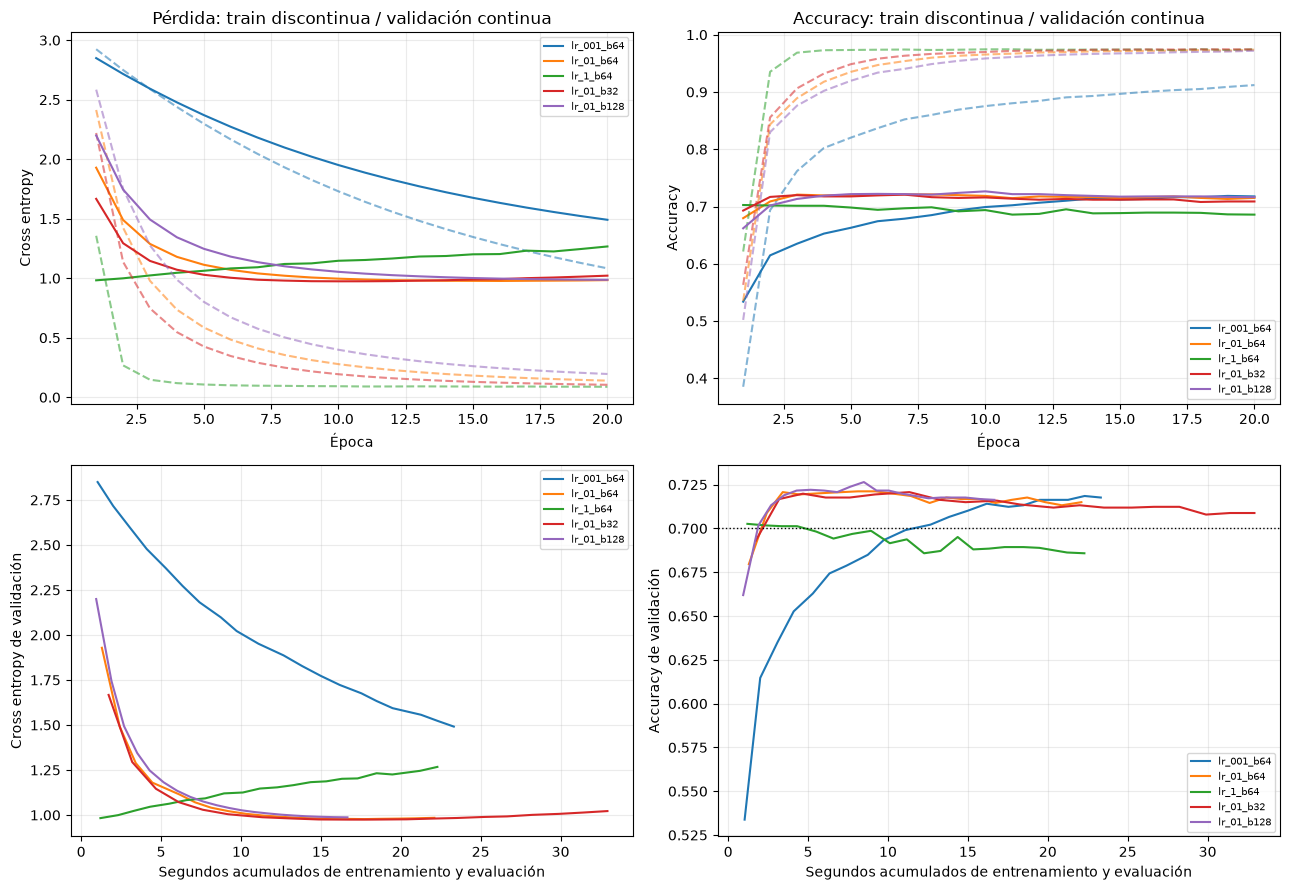

In [18]:
comparison_cases = [('lr_001_b64', .001, 64), ('lr_01_b64', .01, 64),
                    ('lr_1_b64', .1, 64), ('lr_01_b32', .01, 32), ('lr_01_b128', .01, 128)]
best = study.best_params
texts, _ = preprocessed_cache[(best['remove_stopwords'], best['normalization'])]
tr_texts, va_texts, y_tr, y_va = train_test_split(texts, newsgroups_train.target,
    test_size=.2, random_state=SEED, stratify=newsgroups_train.target)
t0 = time.perf_counter()
X_cmp_tr, X_cmp_va, _ = vectorize_data(tr_texts, va_texts,
    (1, 1) if best['ngram_range']=='1gram' else (1, 2), best['max_features'], best['min_df'])
comparison_vectorization_seconds = time.perf_counter()-t0
comparisons = {}
for name, lr, batch_size in comparison_cases:
    params = dict(best, lr=lr, batch_size=batch_size)
    model_cmp, _, record = run_experiment(name, params, X_cmp_tr, y_tr, X_cmp_va, y_va,
        epochs=20, vectorization_seconds=comparison_vectorization_seconds)
    comparisons[name] = record
    del model_cmp
del X_cmp_tr, X_cmp_va

def convergence_stats(record):
    h = record['history']
    reference, stale, stabilized = float('inf'), 0, None
    for i, loss in enumerate(h['val_loss']):
        if reference - loss >= .001:
            reference, stale = loss, 0
        else:
            stale += 1
        if stale >= 3 and stabilized is None:
            stabilized = i + 1
    target = next((i+1 for i, a in enumerate(h['val_acc']) if a >= .70), None)
    return dict(val_acc=h['val_acc'][-1], train_acc=h['train_acc'][-1],
        min_val_loss=min(h['val_loss']), best_loss_epoch=int(np.argmin(h['val_loss']))+1,
        stabilization_epoch=stabilized,
        stabilization_seconds=h['elapsed_seconds'][stabilized-1] if stabilized else None,
        target_epoch=target, target_seconds=h['elapsed_seconds'][target-1] if target else None,
        training_seconds=record['training_seconds'], updates=record['total_updates'])

comparison_rows = [dict(case=name, lr=rec['params']['lr'],
    batch=rec['params']['batch_size'], **convergence_stats(rec)) for name, rec in comparisons.items()]
display(pd.DataFrame(comparison_rows).round(4).fillna('No alcanzado'))
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for name, rec in comparisons.items():
    h = rec['history']
    epochs = range(1, 21)
    line, = axes[0,0].plot(epochs, h['val_loss'], label=name)
    axes[0,0].plot(epochs, h['train_loss'], '--', color=line.get_color(), alpha=.55)
    axes[0,1].plot(epochs, h['val_acc'], label=name)
    axes[0,1].plot(epochs, h['train_acc'], '--', color=line.get_color(), alpha=.55)
    axes[1,0].plot(h['elapsed_seconds'], h['val_loss'], label=name)
    axes[1,1].plot(h['elapsed_seconds'], h['val_acc'], label=name)
for ax, ylabel in zip(axes.flat, ['Cross entropy', 'Accuracy', 'Cross entropy de validación', 'Accuracy de validación']):
    ax.set_ylabel(ylabel)
    ax.grid(alpha=.25)
    ax.legend(fontsize=7)
axes[0,0].set_title('Pérdida: train discontinua / validación continua')
axes[0,1].set_title('Accuracy: train discontinua / validación continua')
for ax in axes[0]: ax.set_xlabel('Época')
for ax in axes[1]: ax.set_xlabel('Segundos acumulados de entrenamiento y evaluación')
axes[1,1].axhline(.70, color='black', ls=':', lw=1)
fig.tight_layout()
plt.show()

### Análisis de dinámica y tiempos de convergencia

| Caso | LR | Batch | Val acc final | Mejor val loss (época) | Estabilización (época; tiempo) | Hasta acc ≥ 0.70 | Tiempo total | Actualizaciones |
|---|---:|---:|---:|---:|---|---|---:|---:|
| `lr_001_b64` | 0.001 | 64 | 71.76 % | 1.4911 (20) | No alcanzada; No alcanzado | 12.66 s | 23.32 s | 2840 |
| `lr_01_b64` | 0.01 | 64 | 71.50 % | 0.9773 (16) | 19; 20.88 s | 2.42 s | 22.10 s | 2840 |
| `lr_1_b64` | 0.1 | 64 | 68.58 % | 0.9827 (1) | 4; 4.31 s | 1.20 s | 22.29 s | 2840 |
| `lr_01_b32` | 0.01 | 32 | 70.88 % | 0.9744 (10) | 12; 20.36 s | 3.19 s | 32.93 s | 5660 |
| `lr_01_b128` | 0.01 | 128 | 71.63 % | 0.9870 (20) | No alcanzada; No alcanzado | 1.89 s | 16.66 s | 1420 |


**Learning rate, batch fijo en 64.** LR 0.001 alcanzó accuracy ≥ 0.70 en 12.66 s; LR 0.01, en 2.42 s; LR 0.1, en 1.20 s. Las accuracies finales fueron 71.76 %, 71.50 % y 68.58 %, respectivamente. La rapidez inicial y la generalización final son criterios distintos: un paso mayor puede reducir rápidamente la pérdida de train y después alejarse del mejor punto de validación.

**Batch size, LR fijo en 0.01.** Para 9051 muestras, batch 32 realiza 283 actualizaciones/época; batch 64, 142; batch 128, 71. En veinte épocas son 5660, 2840 y 1420 actualizaciones. Se midieron 32.93, 22.10 y 16.66 s, con accuracy final 70.88 %, 71.50 % y 71.63 %. No es una comparación a igual cantidad de actualizaciones: justamente muestra por qué época, pasos y tiempo son magnitudes distintas. Las curvas contra segundos permiten comparar el costo observado de alcanzar un resultado.

- **lr_001_b64**: train loss 2.9241 → 1.0833; val loss 2.8494 → 1.4911. La brecha train–val de accuracy al final es 19.44 puntos. La pérdida final de validación queda cerca de su mínimo observado; eso no demuestra convergencia matemática.
- **lr_01_b64**: train loss 2.4137 → 0.1399; val loss 1.9289 → 0.9844. La brecha train–val de accuracy al final es 25.88 puntos. La pérdida final de validación queda cerca de su mínimo observado; eso no demuestra convergencia matemática.
- **lr_1_b64**: train loss 1.3567 → 0.0883; val loss 0.9827 → 1.2672. La brecha train–val de accuracy al final es 28.87 puntos. La pérdida de validación termina por encima de su mínimo mientras train sigue ajustándose; es evidencia de sobreajuste en este presupuesto.
- **lr_01_b32**: train loss 2.2206 → 0.1050; val loss 1.6671 → 1.0218. La brecha train–val de accuracy al final es 26.56 puntos. La pérdida de validación termina por encima de su mínimo mientras train sigue ajustándose; es evidencia de sobreajuste en este presupuesto.
- **lr_01_b128**: train loss 2.5843 → 0.1958; val loss 2.1996 → 0.9870. La brecha train–val de accuracy al final es 25.57 puntos. La pérdida final de validación queda cerca de su mínimo observado; eso no demuestra convergencia matemática.

La columna «estabilización» implementa el criterio declarado antes de correr: tres épocas sin mejora suficiente de val_loss. Puede activarse porque la validación empeora, aunque train siga mejorando. Por eso se reportan también mínimo de pérdida, accuracy y umbral común; no se llama convergencia matemática a una meseta ni se presenta el total de veinte épocas como tiempo de convergencia. «No alcanzado» no se reemplaza por una extrapolación.

Las mediciones corresponden a CPU, dos hilos, una semilla y una sola ejecución por caso. No se midió variabilidad por repeticiones ni se controló la carga de otras aplicaciones. Diferencias pequeñas de tiempo o accuracy no bastan para declarar superioridad general. La métrica de train se acumula mientras los pesos cambian y validación se mide al final; esa asimetría, heredada del profesor, también limita la comparación directa de ambas curvas.

La curva de LR 0.001 todavía reduce claramente la pérdida al llegar a veinte épocas: con este presupuesto aprende más lentamente. LR 0.1 llega pronto al umbral de accuracy, pero su pérdida de validación empeora desde un mínimo temprano; «estabiliza» a la época 4 porque dejó de mejorar, no porque alcanzó una solución preferible. LR 0.01 ofrece una caída de pérdida más sostenida antes de aplanarse. No se observaron NaN ni pérdidas numéricamente divergentes; el problema del caso rápido es su generalización.

LR 0.001 y LR 0.01 terminan con accuracies cercanas aunque sus pérdidas son distintas. Accuracy depende solamente del argmax; cross entropy también penaliza la probabilidad asignada a la clase verdadera. Una mejora de confianza en algunos aciertos, o errores cada vez más seguros, puede modificar mucho la pérdida sin una variación semejante de accuracy.


## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

### Explicación: entrenamiento final y seguimiento

`study.best_params` recupera los hiperparámetros elegidos con validación. Se ajusta un vectorizador nuevo con **todo el train oficial** y se entrenan pesos nuevos durante veinte épocas. No se continúa el modelo del mejor trial ni el de las comparaciones.

MLflow registra los parámetros, las métricas y el modelo final de la ejecución. TensorBoard recibe sus curvas. El vectorizador final permanece en `vectorizer_final` y el modelo en `model`; para predecir textos nuevos hay que aplicar también el mismo preprocesamiento y ese vectorizador. Un modelo exportado por MLflow no incluye automáticamente todo el pipeline de texto.

El profesor pasa `test_loader_final` a la función de entrenamiento como conjunto evaluado: las claves internas `val_loss` y `val_acc` representan aquí **test**. Se rotulan como test en los registros y gráficos. Sus curvas son descriptivas; no se usan para cambiar hiperparámetros ni para elegir retrospectivamente la época del modelo entregado.

In [19]:
best = study.best_params
BEST_REMOVE_SW, BEST_NORM = best['remove_stopwords'], best['normalization']
BEST_NGRAM = (1, 1) if best['ngram_range'] == '1gram' else (1, 2)
BEST_MAX_FEATURES, BEST_MIN_DF = best['max_features'], best['min_df']
BEST_LR, BEST_BATCH_SIZE = best['lr'], best['batch_size']
EPOCHS_FINAL = 20
# Configuración elegida con validación; veinte épocas fijadas antes de observar test.
train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
t0 = time.perf_counter()
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF)
final_vectorization_seconds = time.perf_counter() - t0
model, history, final_record = run_experiment('softmax_final', dict(best),
    X_train_final, newsgroups_train.target, X_test_final, newsgroups_test.target,
    epochs=EPOCHS_FINAL, eval_name='test', vectorization_seconds=final_vectorization_seconds)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target),
    batch_size=BEST_BATCH_SIZE, shuffle=False)
# MLflow registra el modelo final de esta ejecución.
with mlflow.start_run(run_id=final_record['mlflow_run_id']):
    mlflow.pytorch.log_model(model, name='model', serialization_format='pickle',
        pip_requirements=[f'torch=={torch.__version__}', f'mlflow=={mlflow.__version__}'])
print('Tiempo del entrenamiento final:', final_record['training_seconds'], 's')

[softmax_final] Epoch 1/20 - train_loss: 2.4548 train_acc: 0.5590 - test_loss: 2.0850 test_acc: 0.6422


[softmax_final] Epoch 2/20 - train_loss: 1.5264 train_acc: 0.8289 - test_loss: 1.6786 test_acc: 0.6629


[softmax_final] Epoch 3/20 - train_loss: 1.0812 train_acc: 0.8729 - test_loss: 1.4814 test_acc: 0.6678


[softmax_final] Epoch 4/20 - train_loss: 0.8330 train_acc: 0.8988 - test_loss: 1.3754 test_acc: 0.6693


[softmax_final] Epoch 5/20 - train_loss: 0.6762 train_acc: 0.9190 - test_loss: 1.3129 test_acc: 0.6683


...

[softmax_final] Epoch 18/20 - train_loss: 0.1921 train_acc: 0.9696 - test_loss: 1.1973 test_acc: 0.6535


[softmax_final] Epoch 19/20 - train_loss: 0.1829 train_acc: 0.9699 - test_loss: 1.2009 test_acc: 0.6531


[softmax_final] Epoch 20/20 - train_loss: 0.1747 train_acc: 0.9704 - test_loss: 1.2035 test_acc: 0.6529


2026/09/30 22:53:43 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Tiempo del entrenamiento final: 25.79372820002027 s


In [20]:
# Opcional: descomentar para abrir TensorBoard dentro de Jupyter.
# %tensorboard --logdir salidas/runs
print('Eventos de TensorBoard generados en salidas/runs')

Eventos de TensorBoard generados en salidas/runs


## 8. Evaluación final

### Explicación: evaluación y matriz de confusión

Con el modelo en evaluación y sin registrar gradientes, se acumulan las clases predichas con `argmax` y sus etiquetas reales. `accuracy_score` calcula la fracción de documentos correctamente clasificados. `classification_report` agrega precision, recall, F1 y cantidad de ejemplos por clase: permite detectar resultados desiguales que una accuracy global puede ocultar. El promedio macro da el mismo peso a cada clase; el ponderado usa sus cantidades de ejemplos.

La matriz de confusión cruza clase real (filas) con predicción (columnas). La diagonal contiene aciertos; las demás celdas identifican confusiones. Para explicar los errores se revisan los pares más confundidos y ejemplos de sus documentos, como en el bloque 7 del notebook de textos de clase.

Las salidas siguientes contienen las mediciones. Las hipótesis temáticas se distinguen de las cantidades verificadas; no se modifica el modelo a partir de estos errores.

In [21]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Accuracy en test: 0.6529

                          precision    recall  f1-score   support

             alt.atheism       0.47      0.46      0.47       319
           comp.graphics       0.59      0.62      0.60       389
 comp.os.ms-windows.misc       0.58      0.59      0.58       394
comp.sys.ibm.pc.hardware       0.59      0.59      0.59       392
   comp.sys.mac.hardware       0.65      0.62      0.64       385
          comp.windows.x       0.73      0.66      0.69       395
            misc.forsale       0.77      0.78      0.78       390
               rec.autos       0.68      0.65      0.67       396
         rec.motorcycles       0.70      0.68      0.69       398
      rec.sport.baseball       0.54      0.81      0.65       397
        rec.sport.hockey       0.88      0.84      0.86       399
               sci.crypt       0.79      0.68      0.73       396
         sci.electronics       0.56      0.56      0.56       393
                 sci.med       0.78      0.73    

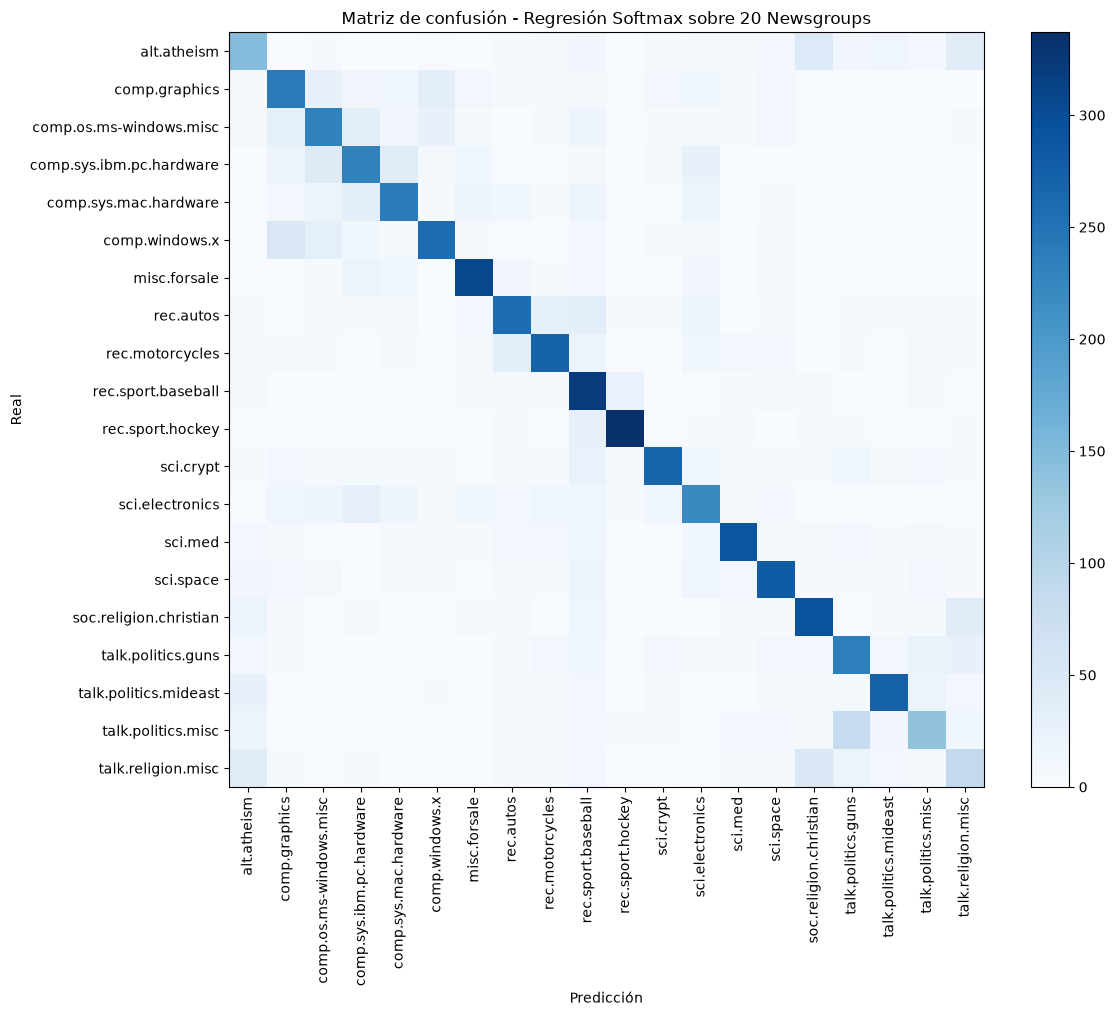

In [22]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
plt.tight_layout()
plt.show()


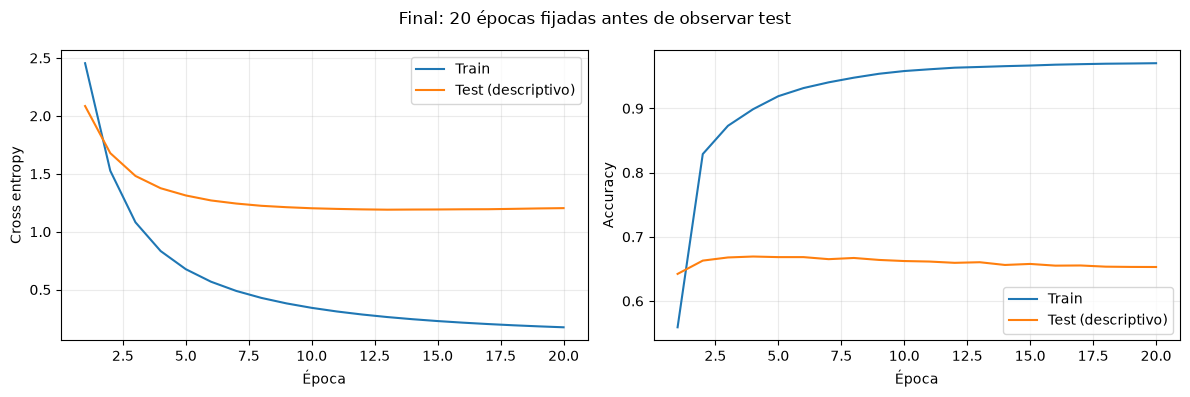

,count,actual,predicted,rate
0,83,talk.politics.misc,talk.politics.guns,0.2677
1,50,talk.religion.misc,soc.religion.christian,0.1992
2,48,comp.windows.x,comp.graphics,0.1215
3,45,alt.atheism,soc.religion.christian,0.1411
4,42,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,0.1071
5,40,comp.sys.ibm.pc.hardware,comp.sys.mac.hardware,0.1020
6,38,talk.religion.misc,alt.atheism,0.1514
7,38,soc.religion.christian,talk.religion.misc,0.0955
8,37,alt.atheism,talk.religion.misc,0.1160
9,34,comp.sys.mac.hardware,comp.sys.ibm.pc.hardware,0.0883


Documento 126 | talk.politics.misc → talk.politics.guns
Can people please stop the 'I think/know the BATF/FBI are completely
responsible but they'll cover it up so that the investigation will
show that Koresch is responsible' bs. In an investigation of this
size with the feds, state, and civilians involved in the
investigation it would be practially impossible to cover up.
And with Republicans like Arlen Spector calling for investigations,
this isn't going to be handled with kid gloves.
Documento 433 | talk.religion.misc → soc.religion.christian




And maybe they do.  But without somebody to set the time that doesn't
do them any good.


Humph.  Deleted there was my list of non-religious reasons one might
want a moment of silence for a dead classmate.

Maybe everyone doesn't want to be silent for teachers to give their
pompous non-religious speeches in assembly.  I know I didn't.  So?



Please provide documentation that opposing only things that are
actively religious (e.g. actual pra

test_accuracy              0.652947
macro_f1                   0.643932
weighted_f1                0.653055
zero_train               320.000000
zero_test                232.000000
nonzero_test_accuracy      0.671370
dtype: float64

In [23]:
from sklearn.metrics import f1_score
report = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1,21), history['train_loss'], label='Train')
axes[0].plot(range(1,21), history['val_loss'], label='Test (descriptivo)')
axes[1].plot(range(1,21), history['train_acc'], label='Train')
axes[1].plot(range(1,21), history['val_acc'], label='Test (descriptivo)')
for ax, ylabel in zip(axes, ['Cross entropy', 'Accuracy']):
    ax.set(xlabel='Época', ylabel=ylabel)
    ax.legend()
    ax.grid(alpha=.25)
fig.suptitle('Final: 20 épocas fijadas antes de observar test')
fig.tight_layout()
plt.show()

pairs = sorted([(int(cm[i,j]), i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i!=j], reverse=True)
confusions = [dict(count=n, actual=class_names[i], predicted=class_names[j],
    rate=n/int(cm[i].sum())) for n,i,j in pairs[:10]]
display(pd.DataFrame(confusions).round(4))
zero_train = int((X_train_final.getnnz(axis=1)==0).sum())
zero_test_mask = X_test_final.getnnz(axis=1)==0
examples = []
for n, i, j in pairs[:3]:
    candidates = np.flatnonzero((np.array(all_labels)==i)&(np.array(all_preds)==j))
    # Mostrar un documento con evidencia léxica, no solo el caso degenerado vacío.
    idx = next((int(k) for k in candidates if not zero_test_mask[k]), int(candidates[0]))
    examples.append(dict(index=idx, actual=class_names[i], predicted=class_names[j],
        excerpt=newsgroups_test.data[idx][:1200], zero_vector=bool(zero_test_mask[idx])))
for example in examples:
    print('Documento', example['index'], '|', example['actual'], '→', example['predicted'])
    print(example['excerpt'])
evaluation = dict(test_accuracy=float(test_accuracy), macro_f1=float(f1_score(all_labels, all_preds, average='macro')),
    weighted_f1=float(f1_score(all_labels, all_preds, average='weighted')),
    zero_train=zero_train, zero_test=int(zero_test_mask.sum()),
    nonzero_test_accuracy=float(accuracy_score(np.array(all_labels)[~zero_test_mask], np.array(all_preds)[~zero_test_mask])),
    confusions=confusions, final_dimensions=[list(X_train_final.shape), list(X_test_final.shape)])
display(pd.Series({k:v for k,v in evaluation.items() if k not in ["confusions", "final_dimensions"]}))

### Resultado final y lectura de errores

Con los hiperparámetros elegidos por Optuna se ajustó TF-IDF sobre **todo el train oficial** y se entrenó un modelo nuevo durante las **20 épocas fijadas de antemano**. Las matrices finales tienen formas `(11314, 10000)` y `(7532, 10000)`; el modelo tiene **200020 parámetros**. No se reutilizan los pesos del trial ganador ni los de las comparaciones.

- Accuracy en los **7532 documentos de test**: **65.29 %**.
- F1 macro: **0.6439**; F1 ponderado: **0.6531**.
- Tiempo del entrenamiento final: **25.79 s**, con la definición de intervalos indicada antes.
- Train accuracy final: 97.04 %; pérdida train final: 0.1747; pérdida test final: 1.2035.

La curva descriptiva de test tuvo pérdida mínima 1.1901 en la época 13, frente a 1.2035 al terminar. Se informa el modelo de la época 20: **no se seleccionó retrospectivamente la época de mejor test ni se reajustaron parámetros después de observarlo**. La diferencia entre train y test se interpreta junto con la pérdida y con las comparaciones sobre validación; no basta la accuracy aislada para evaluar sobreajuste. La accuracy del trial ganador se midió en otra partición y con cinco épocas: no es directamente equivalente a esta evaluación final.

Confusiones dirigidas más frecuentes (fila real → columna predicha):

| Clase real | Predicción errónea | Documentos | % dentro de la clase real |
|---|---|---:|---:|
| talk.politics.misc | talk.politics.guns | 83 | 26.77 % |
| talk.religion.misc | soc.religion.christian | 50 | 19.92 % |
| comp.windows.x | comp.graphics | 48 | 12.15 % |
| alt.atheism | soc.religion.christian | 45 | 14.11 % |
| comp.sys.ibm.pc.hardware | comp.os.ms-windows.misc | 42 | 10.71 % |


Los recalls más bajos fueron `talk.religion.misc` (34.66 %), `talk.politics.misc` (43.87 %), `alt.atheism` (46.08 %). La cantidad de errores y la tasa dentro de cada clase responden preguntas distintas; ambas se muestran para no atribuir automáticamente mayor dificultad a las clases más numerosas. Macro F1 pondera por igual las veinte clases, mientras que F1 ponderado usa sus soportes.

Hay **320 vectores nulos en train y 232 en test** después del pipeline. Para esas entradas, $Wx+b=b$: el clasificador recibe exactamente la misma información y decide por los bias. Pueden originarse en documentos vacíos tras quitar metadata, filtrado de tokens o vocabulario fuera de cobertura. No se eliminaron del TP. Como diagnóstico posterior, excluyendo los vectores nulos la accuracy es 67.14 %; **la métrica principal sigue incluyendo todos los documentos**.

Los ejemplos impresos usan documentos reales del test en los tres pares más confundidos; se elige el primer error con vector no nulo en cada par, para inspeccionar contenido y no únicamente entradas degeneradas. Es una ilustración seleccionada, no una muestra representativa ni una nueva evaluación. Las explicaciones temáticas de abajo son hipótesis apoyadas en esa inspección, sin afirmar causas demostradas.

En la corrida final la accuracy de train llega a 97.04 %, mientras test queda en 65.29 %. Junto con el descenso sostenido de train loss y el aumento de test loss después de la época 13, esto es compatible con sobreajuste, como en las curvas de regularización vistas en clase. Se conserva el presupuesto de veinte épocas de la consigna. Como trabajo futuro se podría estudiar regularización o early stopping usando únicamente validación; no se implementan aquí para mejorar retrospectivamente este test.


## 9. Preguntas de reflexión

**Sobre Regresión Softmax (teoría)**
1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?
2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?
3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?
4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?

**Sobre frameworks y herramientas**
5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?
6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?
7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?

**Sobre el experimento**
8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?
9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?
10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?


## Respuestas a las diez preguntas

### 1. Generalización de la regresión logística binaria

La regresión softmax asigna probabilidades a $K$ clases mutuamente excluyentes mediante $p_k=e^{z_k}/\sum_j e^{z_j}$, con $z=Wx+b$. Para dos clases:

$$p_1=\frac{e^{z_1}}{e^{z_0}+e^{z_1}}=\sigma(z_1-z_0).$$

Por lo tanto, con `NUM_CLASSES=2` expresa la misma familia de probabilidades que una regresión logística binaria: el logit efectivo es $(w_1-w_0)^Tx+(b_1-b_0)$. Se conservan dos salidas y etiquetas 0/1 con CrossEntropyLoss; una implementación binaria alternativa usa un solo logit con BCEWithLogitsLoss. La equivalencia funcional no obliga a que el entrenamiento ni los parámetros redundantes sean idénticos.

### 2. Por qué no se aplica softmax antes de CrossEntropyLoss

Con etiquetas enteras, `CrossEntropyLoss` calcula log-softmax y la pérdida de la clase correcta de manera numéricamente estable: $\ell=-z_y+\log\sum_j e^{z_j}$. El forward devuelve logits. Si se le pasan probabilidades $p=\operatorname{softmax}(z)$, las interpreta como nuevos logits y optimiza $-p_y+\log\sum_j e^{p_j}$: cambia tanto la pérdida como el gradiente. No equivale a la entropía cruzada deseada y comprime el rango de valores. Softmax se usa fuera de la pérdida si se quieren mostrar probabilidades; para predecir alcanza `argmax(logits)`.

### 3. Frontera de decisión y separabilidad

La frontera entre las clases $i$ y $j$ cumple $(w_i-w_j)^Tx+(b_i-b_j)=0$: es un hiperplano en el espacio TF-IDF. La región de una clase es la intersección de las desigualdades frente a las demás. El modelo no aprende interacciones no lineales entre esas coordenadas. Si la separación requiere una transformación no lineal de las features, esta familia puede ser insuficiente, por más que se optimicen sus pesos. «Lineal» se refiere al espacio construido por TF-IDF, no a las cadenas de texto sin transformar.

### 4. Diferencia con una red con capas ocultas

Un MLP con activaciones no lineales aprende representaciones intermedias y fronteras más flexibles. Apilar solo capas lineales seguiría siendo una transformación afín. Elegiría softmax como baseline interpretable y económico para vectores TF-IDF de alta dimensión, especialmente si las palabras ya separan bien los temas. Consideraría capas ocultas cuando haya evidencia de interacciones útiles no capturadas y datos suficientes para ajustar y validar la mayor capacidad. También aumentan parámetros, costo y riesgo de sobreajuste. En este TP se mantiene la única capa pedida; no se ensayó un MLP.

### 5. PyTorch frente a LogisticRegression de scikit-learn

PyTorch expone logits, autograd, pérdida, mini-batches y actualización con Adam: permite entender el procedimiento de clase y modificarlo, instrumentarlo o extenderlo. A cambio requiere programar y verificar el loop, los tipos de etiquetas, las métricas y los registros; aquí también densificamos TF-IDF, con mayor consumo de RAM.

`LogisticRegression` ofrece una interfaz de ajuste/predicción compacta, solvers especializados e integración con pipelines y búsquedas de scikit-learn, y admite matrices dispersas. Sus defaults incluyen regularización y un criterio de parada propios; no sería una comparación idéntica contra veinte épocas de Adam sin penalización. Habría que alinear representación, particiones, regularización y tolerancia/presupuesto antes de interpretar diferencias.

La pregunta conserva `multi_class="multinomial"` del original. En **scikit-learn 1.9.1** ese argumento ya no figura en la firma instalada; con un solver compatible como `lbfgs`, el problema multiclase usa la pérdida multinomial. No se ejecutó esa alternativa en este TP. Véase la [API oficial](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

### 6. Uso concreto de MLflow y TensorBoard

Se registraron **21 corridas independientes** en MLflow: quince trials, cinco comparaciones y un entrenamiento final. Cada una vincula hiperparámetros, semilla, dimensión, muestras, métricas por época y tiempos. El modelo final se registra como artefacto. Los historiales usados para tablas y gráficos son las variables que devuelven los entrenamientos. TensorBoard recibe pérdida y accuracy de train y validación/test, en directorios separados, para superponer e inspeccionar curvas. Ambas herramientas pueden registrar métricas; la distinción aquí es el uso realizado, no una imposibilidad de sus APIs. Todo el tracking es local.

### 7. Ventaja concreta de Optuna

Automatiza propuestas, ejecución y ranking con una función objetivo común y evita comparar a mano configuraciones bajo criterios distintos. El sampler TPE, con semilla 42, usa una fase inicial aleatoria de diez trials y luego información previa para proponer las siguientes combinaciones. Se buscan juntos parámetros de representación y entrenamiento, con LR en escala logarítmica. Eso ahorra coordinación manual, pero quince trials no garantizan el óptimo ni permiten aislar por sí solos el efecto de cada factor.

### 8. Mejor combinación de preprocesamiento e interpretación

Ganó el trial **2**: stopwords `False`, normalización `lemmatize`, n-gramas `1gram`, máximo 10000 features y min_df 2, junto con LR 0.01096822 y batch 128. Obtuvo **72.21 %** de validación en cinco épocas.

Es compatible con el problema de temas de foros: reúne algunas variantes mediante WordNet y conserva formas léxicas; en este código usa el POS nominal predeterminado; conservar stopwords puede retener pistas de estilo o combinaciones; IDF ya reduce relativamente el peso de términos muy comunes; los unigramas pueden capturar vocabulario temático sin gastar columnas en combinaciones más escasas. Son interpretaciones plausibles, no una atribución causal a cada opción. El ganador depende de la combinación, el split, la semilla y el presupuesto. No se usa test para justificar un cambio posterior del pipeline.

### 9. Categorías más confundidas

| Clase real | Predicción errónea | Documentos | % dentro de la clase real |
|---|---|---:|---:|
| talk.politics.misc | talk.politics.guns | 83 | 26.77 % |
| talk.religion.misc | soc.religion.christian | 50 | 19.92 % |
| comp.windows.x | comp.graphics | 48 | 12.15 % |
| alt.atheism | soc.religion.christian | 45 | 14.11 % |
| comp.sys.ibm.pc.hardware | comp.os.ms-windows.misc | 42 | 10.71 % |


Los pares se interpretan en el análisis temático de los ejemplos, agregado debajo. Comparten vocabulario, objetos de discusión o contexto; TF-IDF no representa por completo intención, posición del autor ni contexto discursivo. También existen mensajes breves y 232 entradas de test sin features activas. Los conteos describen el modelo entrenado y deben leerse junto con los recalls por clase; no son una propiedad universal del dataset.

### 10. Qué cambiaría con capas ocultas

Podría cambiar la distribución de errores: activaciones no lineales permiten combinar términos de una manera que la única capa lineal no puede. Eso no demuestra que se reduzcan estas confusiones. Los textos con temas superpuestos seguirían siendo ambiguos, y una red que recibe el mismo TF-IDF no recupera el orden descartado ni distingue documentos con el mismo vector nulo. La mayor capacidad también puede sobreajustar. Habría que comparar ambos modelos sobre la misma validación, con ajuste apropiado y sin volver a seleccionar usando este test. Aquí no se entrenó una red oculta, por lo que la respuesta es una hipótesis de capacidad, no un resultado experimental.

### Interpretación temática de los errores (pregunta 9)

- **Política general → armas (83 casos).** El documento 126 discute responsabilidades del BATF/FBI y una investigación con autoridades federales y civiles. Ese vocabulario puede aparecer tanto en política general como en discusiones sobre armas y actuación de agencias. El clasificador por términos puede asociarlo al segundo grupo aunque la etiqueta sea política general. Es una hipótesis sobre el solapamiento temático, no una demostración basada en atribuciones de pesos.
- **Religión general → cristianismo (50 casos).** El documento 433 debate oración, momentos de silencio, religión estatal y la presencia de la Biblia en una escuela. Los términos son compatibles con el foro cristiano, pero el texto trata una discusión más amplia sobre religión e instituciones. El unigram bag-of-words no modela explícitamente la postura del autor ni las relaciones discursivas.
- **X Window → gráficos (48 casos).** El documento 1 pregunta por imágenes X-Face, un visor y herramientas para mostrarlas. Hay contenido gráfico concreto dentro de un foro sobre X Window, por lo que ambas categorías comparten términos y aplicaciones. Además, el filtrado y la representación por unigramas descartan parte de la forma de los nombres técnicos y del contexto.

Los ejemplos se identifican por su índice en el test oficial y su contenido aparece en la salida de la celda de evaluación. No prueban que todos los errores del par tengan la misma causa. La matriz también muestra confusiones entre ateísmo/religiones y entre categorías de hardware/software; el modelo clasifica foros con fronteras temáticas parcialmente superpuestas.

### Referencias

- [Consigna y notebook inicial](https://github.com/cselmo/TP-Regresion-Softmax-TNG/blob/9267a2ff7839aad6fdceda2185baedabca9a4697/01_Softmax_Regression_20Newsgroups.ipynb): modelo, TODO, búsqueda y preguntas.
- Material de clase de la cátedra: Clasificación de textos (bloques 2–3 y 5–7), PyTorch, Backpropagation, Optimizadores (págs. 3–11 y 22–23), Regularización (págs. 7–13 y 43–47) y Multilayer Perceptron (págs. 7–14). Fundamentan el pipeline, los gradientes, la lectura de curvas y la comparación de capacidades.
- [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html): parámetros y normalización por defecto.
- [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html): entradas como logits y cálculo de la pérdida.
- [MLflow](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.html) y [Optuna](https://optuna.readthedocs.io/en/stable/faq.html): seguimiento de corridas y semillas.

Las explicaciones, resultados y respuestas necesarios para leer el trabajo se incluyen en este notebook. Las referencias respaldan las decisiones; no es necesario disponer de la carpeta de materiales de clase para ejecutarlo.